# CircuitEvolve v2 — group meeting

Two-tier LLM-assisted fault-tolerant (Clifford+T) compilation on the Nam et al. arithmetic suite, with one verifier
deciding every result. This notebook runs **offline**: no network and no LLM calls. The LLM exchanges shown are
replayed from cached records of the real DEV run (`notebooks/v2_assets/tier1_cached_records.json`, copied verbatim
from `results/v2/tier1/logs/`); compilation, verification and rule application run live. Every number is computed
here or read from `results/v2/`, `benchmarks/nam_arith/` or the reused baseline files.

In [1]:
import json, sys, time, math, ast
from collections import Counter
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

T0 = time.time()
ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
ASSETS = ROOT / "notebooks" / "v2_assets"
R2 = ROOT / "results" / "v2"
BENCH = ROOT / "benchmarks" / "nam_arith"
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_columns", 40)

from circuitevolve import integrity
from circuitevolve.v2 import verify as V, metric as M, baselines as BL
DIGEST0 = integrity.frozen_digest()
V.check_integrity()
CACHED = json.loads((ASSETS / "tier1_cached_records.json").read_text())["records"]
print("frozen verifier digest:", DIGEST0[:16], "| frozen files:", len(integrity.FROZEN))
print("cached LLM records:", {k: v["_source"] for k, v in CACHED.items()})

frozen verifier digest: bc3eac23a403dbc5 | frozen files: 8
cached LLM records: {'cuccaro_8_call2': 'results/v2/tier1/logs/dev_v1_cuccaro_8_llm.jsonl:3', 'cuccaro_4_call4': 'results/v2/tier1/logs/dev_v1_cuccaro_4_llm.jsonl:5'}


## 1. The two-tier idea

**Tier 1 (compilation strategy):** the LLM reads a recognizer summary of a *logical* (Toffoli-level) circuit and returns
a JSON plan that picks a known construction per subroutine (Gidney temporary AND, Jones 4-T Toffoli, relative-phase
Toffoli, ...); a deterministic compiler executes it and the result is verified against the logical circuit.
**Tier 2 (optimization):** the LLM writes *executable* rewrite rules (pattern → replacement); each rule is proven once as
an exact identity, applied wherever it matches, and a library version is kept only if it lowers DEV T-count.

| role | tier 1 | tier 2 |
|---|---|---|
| mutator (LLM) | `tier1/prompt.py`, `tier1/loop.py` → plan in `tier1/plan.py` format | `tier2/evolve.py` → `RULE` blocks parsed by `tier2/rules.py` |
| executor | `tier1/recognize.py` + `tier1/compile.py` | `tier2/apply.py` (matcher) + `tier2/commute.py` |
| verifier | `v2/verify.py` (`exact` / `relaxed`) vs the logical circuit | `rules.verify_rule` (`exact`, once per rule) + whole-circuit guards |
| metric | `v2/metric.py` (T, qubits, ancillas, measurements, T-depth) | (T, gates) lexicographic, `v2/metric.py` |
| no-LLM control | `tier1/control.py` (route sets V1-V4 × global passes) | `tier2/enumerate_ids.py` (Quartz-style enumeration) |

The verifier has three labelled modes: **exact** (same qubits, U_cand = c·U_ref over D[ω]), **approx** (phase-aligned
operator distance ≤ ε for continuous rotations) and **relaxed** (clean ancillas, measurement + feed-forward, correct on
every valid input and branch with an input-independent phase). The cell below runs one toy case per mode.

In [2]:
import circuitevolve.v2.tier1.recognize, circuitevolve.v2.tier1.plan, circuitevolve.v2.tier1.compile
import circuitevolve.v2.tier1.control, circuitevolve.v2.tier2.rules, circuitevolve.v2.tier2.apply
import circuitevolve.v2.tier2.enumerate_ids, circuitevolve.v2.tier2.evolve
mods = [V, M, BL] + [sys.modules[f"circuitevolve.v2.{m}"] for m in
        ("tier1.recognize", "tier1.plan", "tier1.compile", "tier1.control", "tier2.rules", "tier2.apply",
         "tier2.enumerate_ids", "tier2.evolve")]
for mod in mods:
    print(f"{mod.__name__.replace('circuitevolve.v2.', ''):20s} {mod.__doc__.strip().splitlines()[0][:105]}")

from circuitevolve.ir import Circuit
ccx = Circuit(3).add("ccx", 0, 1, 2)
gidney = Circuit(4).add("and_compute", 0, 1, 3).add("cx", 3, 2).add("and_uncompute", 0, 1, 3)   # Toffoli via a temporary AND on ancilla q3
cases = [
    ("exact",   "ccx -> 7-T Clifford+T expansion",          V.verify(ccx.expand("clifford_t"), ccx, "exact")),
    ("approx",  "rz(0.3 + 1e-10) vs rz(0.3), eps 1e-8",     V.verify(([("rz", (0,), 0.3 + 1e-10)], 1), ([("rz", (0,), 0.3)], 1), "approx", eps=1e-8)),
    ("approx",  "rz(0.3 + 1e-6) vs rz(0.3), eps 1e-8",      V.verify(([("rz", (0,), 0.3 + 1e-6)], 1), ([("rz", (0,), 0.3)], 1), "approx", eps=1e-8)),
    ("relaxed", "ccx via Gidney AND on a fresh ancilla",    V.verify(gidney, ccx, "relaxed", data_map=[0, 1, 2])),
]
display(pd.DataFrame([dict(mode=m, case=c, ok=v.ok, method=v.method, certified=v.certified,
                           unitary_preserving=v.unitary_preserving, distance=v.distance, reason=v.reason[:60])
                      for m, c, v in cases]))

verify               v2 verifier: ONE entry point for both tiers, three labelled modes.
metric               v2 metric: T-count under BQSKit's error convention, plus qubits, ancillas, measurements, T-depth.
baselines            Reused classical baseline numbers (never recomputed here).
tier1.recognize      Tier 1, part 1: deterministic subroutine recognition on a LOGICAL circuit.
tier1.plan           Tier 1, part 2: the COMPILATION PLAN format, toolbox, and literal parser (json + regex; never exec/eval).
tier1.compile        Tier 1, part 3: execute a compilation plan deterministically, then verify against the LOGICAL circuit.
tier1.control        Tier 1 NO-LLM CONTROL: deterministic plans from the recognizer output, evaluated at the same budget as th
tier2.rules          Tier-2 executable rewrite rules: pattern -> replacement templates over qubit VARIABLES a, b, c, d.
tier2.apply          Apply a tier-2 rule library to an exact Clifford+T circuit, to a fixpoint.
tier2.enumerate_ids  No

,mode,case,ok,method,certified,unitary_preserving,distance,reason
0,exact,ccx -> 7-T Clifford+T expansion,True,basis-exhaustive,True,True,0.000000e+00,
1,approx,"rz(0.3 + 1e-10) vs rz(0.3), eps 1e-8",True,unitary,True,True,5.000001e-11,
2,approx,"rz(0.3 + 1e-6) vs rz(0.3), eps 1e-8",False,unitary,True,True,5.000000e-07,distance 5.000e-07 > eps 1.000e-08
3,relaxed,ccx via Gidney AND on a fresh ancilla,True,branchwise-exhaustive,True,False,0.000000e+00,


## 2. Benchmarks and baselines

The v2 suite (`benchmarks/nam_arith/MANIFEST.csv`, split `v2-nam-arith-1` in `SPLIT.md`) is the Nam et al. 2018 /
T-par arithmetic suite plus generated Cuccaro adders and qseed Shor circuits. DEV holds the smallest instances of each
family; held-out holds strictly larger instances plus whole families with no DEV member. Baselines are **reused**, never
recomputed: our pyzx / TKET runs (`results/v2/baselines_new.csv`), the stage-1 BQSKit table, the old reference pipelines,
and published values (context only).

In [3]:
man = pd.read_csv(BENCH / "MANIFEST.csv")
split = json.loads((BENCH / "split_v2.json").read_text())
fam = (man.groupby(["family", "split"]).agg(circuits=("name", lambda s: ", ".join(s)), qubits_min=("qubits", "min"),
                                           qubits_max=("qubits", "max")).reset_index().sort_values(["split", "family"]))
print(f"{len(man)} circuits; split {split.get('version')}: dev {len(split['dev'])}, held-out {len(split['heldout'])}, "
      f"large_optional {len(split.get('large_optional', []))}")
display(fam)
tab = BL.table()
src = (tab.groupby("source").agg(rows=("circuit", "size"), circuits=("circuit", "nunique"), valid=("valid", "sum"),
                                 comparable=("comparable", "sum")).reset_index())
display(src)

40 circuits; split v2-nam-arith-1: dev 17, held-out 22, large_optional 1


,family,split,circuits,qubits_min,qubits_max
0,adder,dev,"cuccaro_4, vbe_adder_3, rc_adder_6, csla_mux_3, cuccaro_8",10,18
3,gf2_mult,dev,"gf2^4_mult, gf2^5_mult, gf2^6_mult",12,18
9,mcx_toffoli,dev,"barenco_tof_3, tof_3, barenco_tof_4, tof_4, barenco_tof_5, tof_5",5,9
11,modular,dev,"mod5_4, mod_mult_55",5,9
13,shor,dev,shor_12,12,12
1,adder,heldout,"adder_8, csum_mux_9, cuccaro_16, qcla_adder_10",24,36
2,comparator,heldout,qcla_com_7,24,24
4,gf2_mult,heldout,"gf2^7_mult, gf2^8_mult, gf2^9_mult, gf2^10_mult, gf2^16_mult",21,48
6,grover_oracle,heldout,grover_5,9,9
7,hamming,heldout,"ham15-low, ham15-med, ham15-high",17,20


,source,rows,circuits,valid,comparable
0,published,61,26,61,0
1,reference_pipelines,15,5,15,15
2,stage1_v2,112,8,80,112
3,v2_new,434,45,434,434


## 3. Tier 1 live demo: `cuccaro_8`

`cuccaro_8` is an 8-bit Cuccaro ripple-carry adder (18 qubits, 16 Toffolis). The deterministic recognizer lists qubit
roles, Toffolis `T<k>` and compute/uncompute pairs `P<k>` with their class (clean / mirror / controls_fixed); this
summary is what the LLM sees. Below: the summary, as computed now.

In [4]:
from circuitevolve.v2.tier1.recognize import load_logical, summarize
from circuitevolve.v2.tier1.compile import evaluate
row = man.set_index("name").loc["cuccaro_8"]
declared_zero = [] if pd.isna(row["zero_init_qubits"]) else [int(x) for x in str(row["zero_init_qubits"]).split()]
orig8, lc8 = load_logical(BENCH / row["logical_path"], name="cuccaro_8")
s8 = summarize(lc8, declared_zero, "cuccaro_8")
norm = V.verify(orig8, V.ReferenceSpec.from_circuit(lc8.to_ir()), "exact")      # normalization check, as the dev runner
print("normalized circuit vs original QASM:", norm.ok, norm.method)
txt = s8.text(lc8).splitlines()
print("\n".join(l[:200] for l in txt[:txt.index(next(l for l in txt if l.startswith("NORMALIZED")))]))

normalized circuit vs original QASM: True basis-sampled
CIRCUIT cuccaro_8: 18 qubits, 49 gates (ccx:16, cx:33); classical reversible (x/cx/ccx + diagonal).
Naive cost: 112 T (7 per Toffoli, 16 Toffolis).
Declared zero-init qubits (benchmark contract, start in |0>): ['q0'].
QUBITS (q: Z=declared zero-init / first touch / R=restored to |0> at end / guessed role):
  q0:Z/cx-target/R/ancilla(clean); q1:-/cx-target/-/data; q2:-/cx-control/-/data; q3:-/cx-target/-/data; q4:-/cx-control/-/data; q5:-/cx-target/-/data; q6:-/cx-control/-/data; q7:-/cx-target/-/data; q
TOFFOLIS (id: gate index, kind, controls -> target):
  T0:g2 ccx q0 q1->q2; T1:g5 ccx q2 q3->q4; T2:g8 ccx q4 q5->q6; T3:g11 ccx q6 q7->q8; T4:g14 ccx q8 q9->q10; T5:g17 ccx q10 q11->q12; T6:g20 ccx q12 q13->q14; T7:g23 ccx q14 q15->q16; T8:g25 ccx q14 
PAIRS (same Toffoli repeated, controls unchanged in between; class: clean = declared-zero target, |0> before, not written between; mirror = target only read between; controls_fixed 

### 3a. One cached LLM compilation plan (DEV run `dev_v1`, `cuccaro_8`, call 2)

Prompt excerpt (objective, toolbox, and the history the model saw) and the model's JSON reply, both verbatim from the
log. The model recognized the pairs as compute/uncompute and routed every pair to Gidney's temporary AND on a fresh
ancilla; the toolbox description it chose from is shown in the excerpt.

In [5]:
rec = CACHED["cuccaro_8_call2"]
P = rec["prompt"].splitlines()
def block(start, stop):
    i = next(k for k, l in enumerate(P) if l.startswith(start))
    j = next(k for k, l in enumerate(P) if k > i and l.startswith(stop)) if stop else len(P)
    return P[i:j]
excerpt = P[:6] + ["[...]"] + block("TOOLBOX", "TECHNIQUE CARDS")[:6] + ["[...]"] + block("BEST VERIFIED", "RECENT")
print(f"prompt: {rec['prompt_chars']} chars, sha256 {rec['prompt_sha256'][:16]}..., cards {rec['cards']}, "
      f"usage {rec['usage']}\n")
print("\n".join(l if len(l) < 240 else l[:237] + "..." for l in excerpt))
print("\nREPLY (JSON plan):")
print(json.dumps(json.loads(rec["reply"]), indent=1))

prompt: 15566 chars, sha256 99492eb834923e2a..., cards ['01_gidney_temporary_and', '03_relative_phase_toffoli', '06_cuccaro_ripple_carry'], usage {'input_tokens': 7877, 'output_tokens': 389}

You choose a fault-tolerant COMPILATION STRATEGY for one logical reversible circuit (Toffoli level). A deterministic compiler executes your plan and an exact verifier checks the result against the logical circuit; only verified results c...

OBJECTIVE: minimise T-count (then qubits, then T-depth). Two separate leaderboards:
- EXACT: unitary-preserving on the same qubits (no measurement, no extra qubit, no zero-init promise).
- RELAXED: may use fresh clean ancillas, mid-circuit measurement + classically controlled fix-ups, and the declared zero-init promise; every ancilla must return to |0> and every measurement branch must act correctly with an input-indepen...
THIS CALL TARGETS: RELAXED.
[...]
TOOLBOX (tier1-toolbox-v1). Routes: name [applies to] (verification mode; T cost): description
- toffoli

### 3b. Compile and verify the replayed plan live

The plan is parsed (json + regex only), compiled with the frozen IR gadgets, and verified against the normalized
logical circuit in **relaxed** mode (the plan adds ancillas and measurements). T is compared with the naive logical
cost and with the best reused unitary-preserving classical number from `baselines.best_classical`.

In [6]:
t1 = time.time()
ev8 = evaluate(lc8, s8, rec["reply"])
dt8 = time.time() - t1
comp8 = ev8["_compiled"]
naive = M.measure(lc8.to_ir())
bc8 = BL.best_classical("cuccaro_8", 0.0)
print(f"verdict: ok={ev8['ok']} mode={ev8['verdict_mode']} method={ev8['method']} certified={ev8['certified']} "
      f"unitary_preserving={ev8['unitary_preserving']}  ({dt8:.1f} s)")
print(f"compiled digest {ev8['digest']} == logged {rec['digest']}: {ev8['digest'] == rec['digest']}")
display(pd.DataFrame([
    dict(circuit="logical (7 T per Toffoli)", T=naive["t_count"], qubits=naive["qubits"], measurements=naive["measurements"], contract="-"),
    dict(circuit=f"best classical ({bc8['arm']})", T=bc8["t_count"], qubits=lc8.n, measurements=0, contract="unitary-preserving"),
    dict(circuit="LLM plan, compiled now", T=ev8["t_count"], qubits=ev8["qubits"], measurements=ev8["measurements"], contract="relaxed"),
    dict(circuit="LLM plan, as logged", T=rec["t_count"], qubits=rec["qubits"], measurements=rec["measurements"], contract=rec["verdict_mode"]),
]))
print(f"T: {naive['t_count']} (logical) -> {ev8['t_count']} (relaxed plan); best classical exact {bc8['t_count']:.0f}; "
      f"ratio {ev8['t_count'] / bc8['t_count']:.2f}; cost +{ev8['ancillas']} ancillas, {ev8['measurements']} measurements")
# one Gidney gadget at the gadget level: the first and_compute / and_uncompute pair of the routed circuit
g = comp8.routed.gates
i = next(k for k, x in enumerate(g) if x.name == "and_compute")
a = g[i].qubits[2]
j = next(k for k, x in enumerate(g) if x.name == "and_uncompute" and x.qubits[2] == a)
print("first temporary AND (ancilla q%d): gates %d..%d:" % (a, i - 1, j + 1),
      "; ".join(f"{x.name} {' '.join('q%d' % q for q in x.qubits)}" for x in g[i - 1:i + 2]), "... ",
      "; ".join(f"{x.name} {' '.join('q%d' % q for q in x.qubits)}" for x in g[j - 1:j + 2]))

verdict: ok=True mode=relaxed method=branchwise-sampled certified=False unitary_preserving=False  (2.5 s)
compiled digest a18c7e60e561ce6d == logged a18c7e60e561ce6d: True


,circuit,T,qubits,measurements,contract
0,logical (7 T per Toffoli),112.0,18,0,-
1,best classical (pyzx_fr),64.0,18,0,unitary-preserving
2,"LLM plan, compiled now",32.0,26,8,relaxed
3,"LLM plan, as logged",32.0,26,8,relaxed


T: 112 (logical) -> 32 (relaxed plan); best classical exact 64; ratio 0.50; cost +8 ancillas, 8 measurements
first temporary AND (ancilla q18): gates 1..63: cx q2 q0; and_compute q0 q1 q18; cx q18 q2 ...  cx q18 q2; and_uncompute q0 q1 q18; cx q2 q0


### 3c. Rejections: one logged LLM plan and one planted plan

The verifier's failure reasons are diagnoses fed back to the LLM. First, a logged LLM plan for `cuccaro_4` (call 4)
that computed a temporary AND directly into a pair's target instead of a fresh ancilla, replayed live. Second, a planted
plan for `cuccaro_8`: `temporary_and` directly on `P0`, whose target `q2` is *dirty* (written between the pair).

In [7]:
rej = CACHED["cuccaro_4_call4"]
row4 = man.set_index("name").loc["cuccaro_4"]
orig4, lc4 = load_logical(BENCH / row4["logical_path"], name="cuccaro_4")
s4 = summarize(lc4, [int(x) for x in str(row4["zero_init_qubits"]).split()] if not pd.isna(row4["zero_init_qubits"]) else [], "cuccaro_4")
ev4 = evaluate(lc4, s4, rej["reply"])
print("cuccaro_4 call 4 decisions:", [(d["element"], d["route"], d.get("via_ancilla")) for d in json.loads(rej["reply"])["decisions"]])
print("  rationale:", json.loads(rej["reply"])["rationale"][:200], "...")
print(f"  live : ok={ev4['ok']} mode={ev4['verdict_mode']} method={ev4['method']} reason: {ev4['reason']}")
print(f"  log  : ok={rej['ok']} reason: {rej['reason']}")
print("  P3 class in the summary:", next(l.strip() for l in s4.text(lc4).splitlines() if l.strip().startswith("P3 =")))

bad = {"target": "relaxed", "global_pass": "none",
       "decisions": [{"element": "P0", "route": "temporary_and"}] +
                    [{"element": f"P{k}", "route": "temporary_and", "via_ancilla": True} for k in range(1, 8)]}
evb = evaluate(lc8, s8, json.dumps(bad))
print("\nplanted cuccaro_8 plan (P0 direct temporary_and on dirty target q2):")
print("  P0 class in the summary:", next(l.strip() for l in txt if l.strip().startswith("P0 =")))
print(f"  live : ok={evb['ok']} stage={evb['stage']} mode={evb['verdict_mode']} method={evb['method']} T would be {evb['t_count']}")
print(f"  reason: {evb['reason']}")

cuccaro_4 call 4 decisions: [('P0', 'temporary_and', True), ('P1', 'temporary_and', True), ('P2', 'temporary_and', True), ('P3', 'temporary_and', False)]
  rationale: P3 is a mirror pair with its target (q8) a clean-written qubit between the two Toffolis only read, not written, so the direct (non-ancilla) temporary_and can compute straight into q8 instead of routin ...
  live : ok=False mode=relaxed method=branchwise-exhaustive reason: input 0x100, branch (0, 0, 0, 0): wrong output: support ['0x7f'] != expected ['0x180']
  log  : ok=False reason: input 0x100, branch (0, 0, 0, 0): wrong output: support ['0x7f'] != expected ['0x180']
  P3 class in the summary: P3 = T3+T4 (g11..g13) target q8 controls q6 q7: mirror

planted cuccaro_8 plan (P0 direct temporary_and on dirty target q2):
  P0 class in the summary: P0 = T0+T15 (g2..g46) target q2 controls q0 q1: controls_fixed
  live : ok=False stage=verify mode=relaxed method=branchwise-sampled T would be 32
  reason: input 0x3ffff, branch (0

## 4. Tier 2 live demo: one verified LLM rule

A verified rule proposed by the LLM in run `run1` (read from `results/v2/tier2/rules_verified.csv`) is re-proven live as
an exact identity (frozen D[ω] simulator, exhaustive over 2^k inputs), shown firing on a toy circuit through a commuting
gate, and then applied to all 16 DEV start circuits (the best verified classical outputs). A planted non-identity is
rejected for contrast.

In [8]:
from circuitevolve.v2.tier2.rules import parse_rules, verify_rule, Library
from circuitevolve.v2.tier2.apply import apply_library, cost
from circuitevolve.v2.tier2.circuits import start_circuits
rv = pd.read_csv(R2 / "tier2" / "rules_verified.csv")
r = rv[(rv.arm == "llm") & (rv.name == "g4p1_t_cz_t_merge")].iloc[0]
rule_text = f"RULE {r['name']}\nPATTERN: {r['pattern']}\nREPLACE: {r['replacement']}\nSIDE: commute\nEND"
print(rule_text, f"\n(logged: gen {r['gen']}, dT={r['dT']}, DEV applications {r['applications_dev']}; meaning: {r['meaning']})")
(rule,), errs = parse_rules(rule_text, "llm")
proof = verify_rule(rule)
print("\nlive proof:", proof)
toy = [("t", (0,)), ("cx", (0, 2)), ("cz", (0, 1)), ("h", (2,)), ("t", (0,))]
res_toy = apply_library(toy, 3, [rule], log_apps=True)
print("toy circuit :", toy, "cost (T, gates)", res_toy["cost_before"])
print("rewritten   :", res_toy["gates"], "cost", res_toy["cost_after"], "apps", dict(res_toy["apps"]))
print("toy rewrite exact check:", V.verify((list((n_, q_, None) for n_, q_ in res_toy["gates"]), 3),
                                           (list((n_, q_, None) for n_, q_ in toy), 3), "exact").ok)
(planted,), _ = parse_rules("RULE planted_bad\nPATTERN: t a; h a; t a\nREPLACE: s a; h a\nEND", "test")
print("planted non-identity:", verify_rule(planted))

RULE g4p1_t_cz_t_merge
PATTERN: t a; cz a b; t a
REPLACE: s a; cz a b
SIDE: commute
END 
(logged: gen 4, dT=2, DEV applications 0; meaning: cz is Z-like and commutes with t on a, so t;cz;t = cz;t;t = cz;s on a, merging two T's into one S (T-count 2->0 locally))

live proof: {'ok': True, 'reason': '', 'method': 'basis-exhaustive', 'certified': True, 'k': 2, 'global_phase': [1.0, 0.0]}
toy circuit : [('t', (0,)), ('cx', (0, 2)), ('cz', (0, 1)), ('h', (2,)), ('t', (0,))] cost (T, gates) (2, 5)
rewritten   : [('cx', (0, 2)), ('h', (2,)), ('s', (0,)), ('cz', (0, 1))] cost (0, 4) apps {'g4p1_t_cz_t_merge': 1}
toy rewrite exact check: True
planted non-identity: {'ok': False, 'reason': 'not an identity: input 0x0: output amplitudes not proportional to the reference output (relative phase inside the state)', 'method': 'basis-exhaustive', 'certified': True, 'k': 1}


In [9]:
starts = start_circuits()
rows = []
for c, st in starts.items():
    res = apply_library(st["gates"], st["n"], [rule])
    rows.append(dict(circuit=c, start=st["arm"], n=st["n"], T=res["cost_before"][0], gates=res["cost_before"][1],
                     matches=sum(res["apps"].values()), T_after=res["cost_after"][0]))
app = pd.DataFrame(rows)
print(f"rule {rule.name} on {len(app)} DEV start circuits: {app.matches.sum()} matches, total T {app['T'].sum()} -> {app.T_after.sum()}")
display(app)
lib = Library.load(R2 / "tier2" / "library_final.json")          # re-verifies every rule and the content hash
print(f"frozen primary library: version {lib.version}, {len(lib.rules)} rules, sha256 {lib.sha256[:16]}...",
      "| .sha256 file:", (R2 / "tier2" / "library_final.sha256").read_text().split()[0][:16])
diag = json.loads((R2 / "tier2" / "diagnostics.json").read_text())
print(f"headroom probe (diagnostics.json): enumerated pool {diag['pool_size']:,} identities "
      f"(specs qubits<=gates {diag['pool_specs']}), {diag['pool_t_reducing']:,} T-reducing; "
      f"T-reducing rules matching any start circuit: {diag['t_reducing_pool_rules_matching_any_start']} "
      f"({diag['t_reducing_pool_total_matches']} matches)")

rule g4p1_t_cz_t_merge on 16 DEV start circuits: 0 matches, total T 758 -> 758


,circuit,start,n,T,gates,matches,T_after
0,barenco_tof_3,nam_light_file,5,16,42,0,16
1,barenco_tof_4,nam_light_file,7,28,78,0,28
2,barenco_tof_5,nam_light_file,9,40,114,0,40
3,csla_mux_3,pyzx_fr,15,62,261,0,62
4,cuccaro_4,pyzx_fr,10,32,160,0,32
5,cuccaro_8,pyzx_fr,18,64,301,0,64
6,gf2^4_mult,nam_light_file,12,68,187,0,68
7,gf2^5_mult,nam_light_file,15,115,296,0,115
8,gf2^6_mult,nam_light_file,18,150,403,0,150
9,mod5_4,pyzx_fr,5,8,51,0,8


frozen primary library: version v0, 0 rules, sha256 4f53cda18c2baa0c... | .sha256 file: 4f53cda18c2baa0c
headroom probe (diagnostics.json): enumerated pool 42,270 identities (specs qubits<=gates [[1, 8], [2, 6], [3, 4]]), 8,833 T-reducing; T-reducing rules matching any start circuit: 0 (0 matches)


## 5. DEV results: LLM vs no-LLM control

Tier 1: best verified T per circuit for the LLM arm and the deterministic control at the same budget (8 compile+verify
evaluations), in both modes, next to the best reused classical (unitary-preserving) number. Tier 2: total DEV T for the
LLM-evolved and enumeration-control libraries. Both tables are read from the DEV CSVs.

In [10]:
d1 = pd.read_csv(R2 / "tier1" / "dev_results.csv")
piv = d1[d1.arm.isin(["llm", "control"])].pivot_table(index="circuit", columns=["mode", "arm"], values="t_count")
piv.columns = [f"{m}_{a}" for m, a in piv.columns]
piv["best_classical"] = d1[d1.arm == "best_classical"].set_index("circuit")["t_count"]
piv = piv[["best_classical", "exact_control", "exact_llm", "relaxed_control", "relaxed_llm"]]
display(piv)
tally = []
for mode in ("exact", "relaxed"):
    l, c = piv[f"{mode}_llm"], piv[f"{mode}_control"]
    tally.append(dict(mode=mode, circuits=len(piv), llm_better=int((l < c).sum()), equal=int((l == c).sum()),
                      llm_worse=int((l > c).sum()), llm_no_valid_plan=int(l.isna().sum()),
                      control_below_classical=int((c < piv.best_classical).sum())))
TALLY1 = pd.DataFrame(tally); display(TALLY1)
run1 = json.loads((R2 / "tier1" / "dev_v1_run.json").read_text())

d2 = pd.read_csv(R2 / "tier2" / "dev_results.csv")
d2 = d2[d2.start_arm != "excluded"]
T2 = pd.DataFrame([dict(arm=a, circuits=len(d2), start_T=int(d2.start_t.sum()), final_T=int(d2[f"{a}_t"].sum()),
                        best_classical_T=int(d2.best_classical_t.sum()), start_gates=int(d2.start_gates.sum()),
                        lex_secondary_gates=int(d2[f"{a}_lex_gates"].sum())) for a in ("llm", "control")])
display(T2)
gens = pd.read_csv(R2 / "tier2" / "generations.csv")
prim = gens[gens.arm.isin(["llm", "control"])]
print("tier-2 primary arms: generations", prim.groupby("arm").gen.max().to_dict(), "| library versions accepted after v0:",
      prim[(prim.gen > 0) & prim.accepted.astype(str).eq("True")].groupby("arm").size().reindex(["llm", "control"], fill_value=0).to_dict(),
      "| final version:", prim.groupby("arm").library_version.last().to_dict())

,best_classical,exact_control,exact_llm,relaxed_control,relaxed_llm
circuit,,,,,
barenco_tof_3,16.0,16.0,16.0,12.0,12.0
barenco_tof_4,28.0,28.0,28.0,24.0,24.0
barenco_tof_5,40.0,40.0,40.0,36.0,36.0
csla_mux_3,45.0,62.0,62.0,40.0,40.0
cuccaro_4,32.0,32.0,32.0,16.0,16.0
cuccaro_8,64.0,64.0,64.0,32.0,32.0
gf2^4_mult,52.0,68.0,68.0,64.0,64.0
gf2^5_mult,86.0,115.0,115.0,100.0,100.0
gf2^6_mult,122.0,150.0,150.0,144.0,NaN


,mode,circuits,llm_better,equal,llm_worse,llm_no_valid_plan,control_below_classical
0,exact,16,0,16,0,0,0
1,relaxed,16,0,13,2,1,10


,arm,circuits,start_T,final_T,best_classical_T,start_gates,lex_secondary_gates
0,llm,16,758,758,652,2380,2378
1,control,16,758,758,652,2380,2310


tier-2 primary arms: generations {'control': 18, 'llm': 18} | library versions accepted after v0: {'llm': 0, 'control': 0} | final version: {'control': 'v0', 'llm': 'v0'}


## 6. Held-out evaluation (frozen artifacts, no LLM arms)

Both LLM arms were null on DEV, so the held-out run (`results/v2/eval/`) evaluates the frozen deterministic tier-1
control, the frozen tier-2 library and their combination against the reused baselines. Unitary-preserving (exact)
and relaxed (ancilla + measurement) results are kept in separate tables; relaxed rows list their qubit and measurement
overhead and the zero-init promise they rely on.

A. unitary-preserving


,n,best_classical_ours,arm,tier1_exact,tier2_v0,tier1+tier2_v0,best_published,check
circuit,,,,,,,,
adder_8,24,173.0,pyzx_fr,173.0,173.0,173.0,167.0,"samp, +2 seeds ok"
barenco_tof_10,19,100.0,nam_light_file,100.0,100.0,100.0,100.0,"samp, +2 seeds ok"
csum_mux_9,30,84.0,nam_light_file,84.0,84.0,84.0,72.0,"samp, +2 seeds ok"
cuccaro_16,34,128.0,pyzx_fr,128.0,128.0,128.0,NaN,"samp, +2 seeds ok"
gf2^10_mult,30,410.0,nam_light_file,410.0,410.0,410.0,410.0,"samp, +2 seeds: time limit on 1,2"
gf2^16_mult,48,1040.0,nam_light_file,1792.0,1040.0,1792.0,1040.0,"samp, +2 seeds ok"
gf2^7_mult,21,217.0,nam_light_file,217.0,217.0,217.0,173.0,"samp, +2 seeds ok"
gf2^8_mult,24,264.0,nam_light_file,264.0,264.0,264.0,214.0,"samp, +2 seeds ok"
gf2^9_mult,27,351.0,nam_light_file,351.0,351.0,351.0,351.0,"samp, +2 seeds ok"


B. relaxed (different contract)


,best_classical_ours,relaxed_T,ratio,qubits,ancillas,measurements,zero_init_promise,variant,check
circuit,,,,,,,,,
adder_8,173.0,180.0,1.04,29,5,40,10 16 17 23,V2 + pyzx,"samp, +2 seeds ok"
barenco_tof_10,100.0,96.0,0.96,28,9,24,none,V2 + pyzx,"samp, +2 seeds ok"
csum_mux_9,84.0,112.0,1.33,31,1,22,10 11 24 25 26 27,V2 + pyzx,"samp, +2 seeds ok"
cuccaro_16,128.0,64.0,0.50,50,16,16,none,V2 + pyzx,"samp, +2 seeds ok"
gf2^10_mult,410.0,400.0,0.98,31,1,91,20 21 22 23 24 25 26 27 28,V2 + pyzx,"samp, +2 seeds: time limit on 1"
gf2^16_mult,1040.0,1024.0,0.98,49,1,241,32 33 34 35 36 37 38 39 40 41 42 43 44 45 46,V2 + pyzx,"samp, +2 seeds ok"
gf2^7_mult,217.0,196.0,0.90,22,1,43,14 15 16 17 18 19,V2 + pyzx,"samp, +2 seeds ok"
gf2^8_mult,264.0,256.0,0.97,25,1,57,16 17 18 19 20 21 22,V2 + pyzx,"samp, +2 seeds ok"
gf2^9_mult,351.0,324.0,0.92,28,1,73,18 19 20 21 22 23 24 25,V2 + pyzx,"samp, +2 seeds ok"


{'n': 18, 'exact_eq': 17, 'exact_worse': 1, 'exact_better': 0, 't2_changed': 0, 'relaxed_lower': 15, 'relaxed_higher': 3, 'relaxed_total': 4968, 'classical_total': 5728, 'min_lower': 15, 'pub_lower': 7, 'pub_n': 15, 'anc_min': 1, 'anc_max': 16, 'meas_min': 9, 'meas_max': 241, 'variants': ['V2 + pyzx'], 'relaxed_pct': -13.268156424581}

not evaluated:
  qcla_adder_10  blocked  BLOCKED (verifier coverage, not a refutation): the recognizer's ccx-normalized logical circuit keeps unfused h/ccz gates, so the reference is not perm
  qcla_com_7     blocked  BLOCKED (verifier coverage, not a refutation): the recognizer's ccx-normalized logical circuit keeps unfused h/ccz gates, so the reference is not perm
  shor_14        skipped  rotation-dominated (continuous cp/ccp); frozen toolbox tier1-toolbox-v1 has no rotation route (same reason as shor_12 on dev); tier 2 is exact Cliffor
  shor_16        skipped  rotation-dominated (continuous cp/ccp); frozen toolbox tier1-toolbox-v1 has no rotation ro

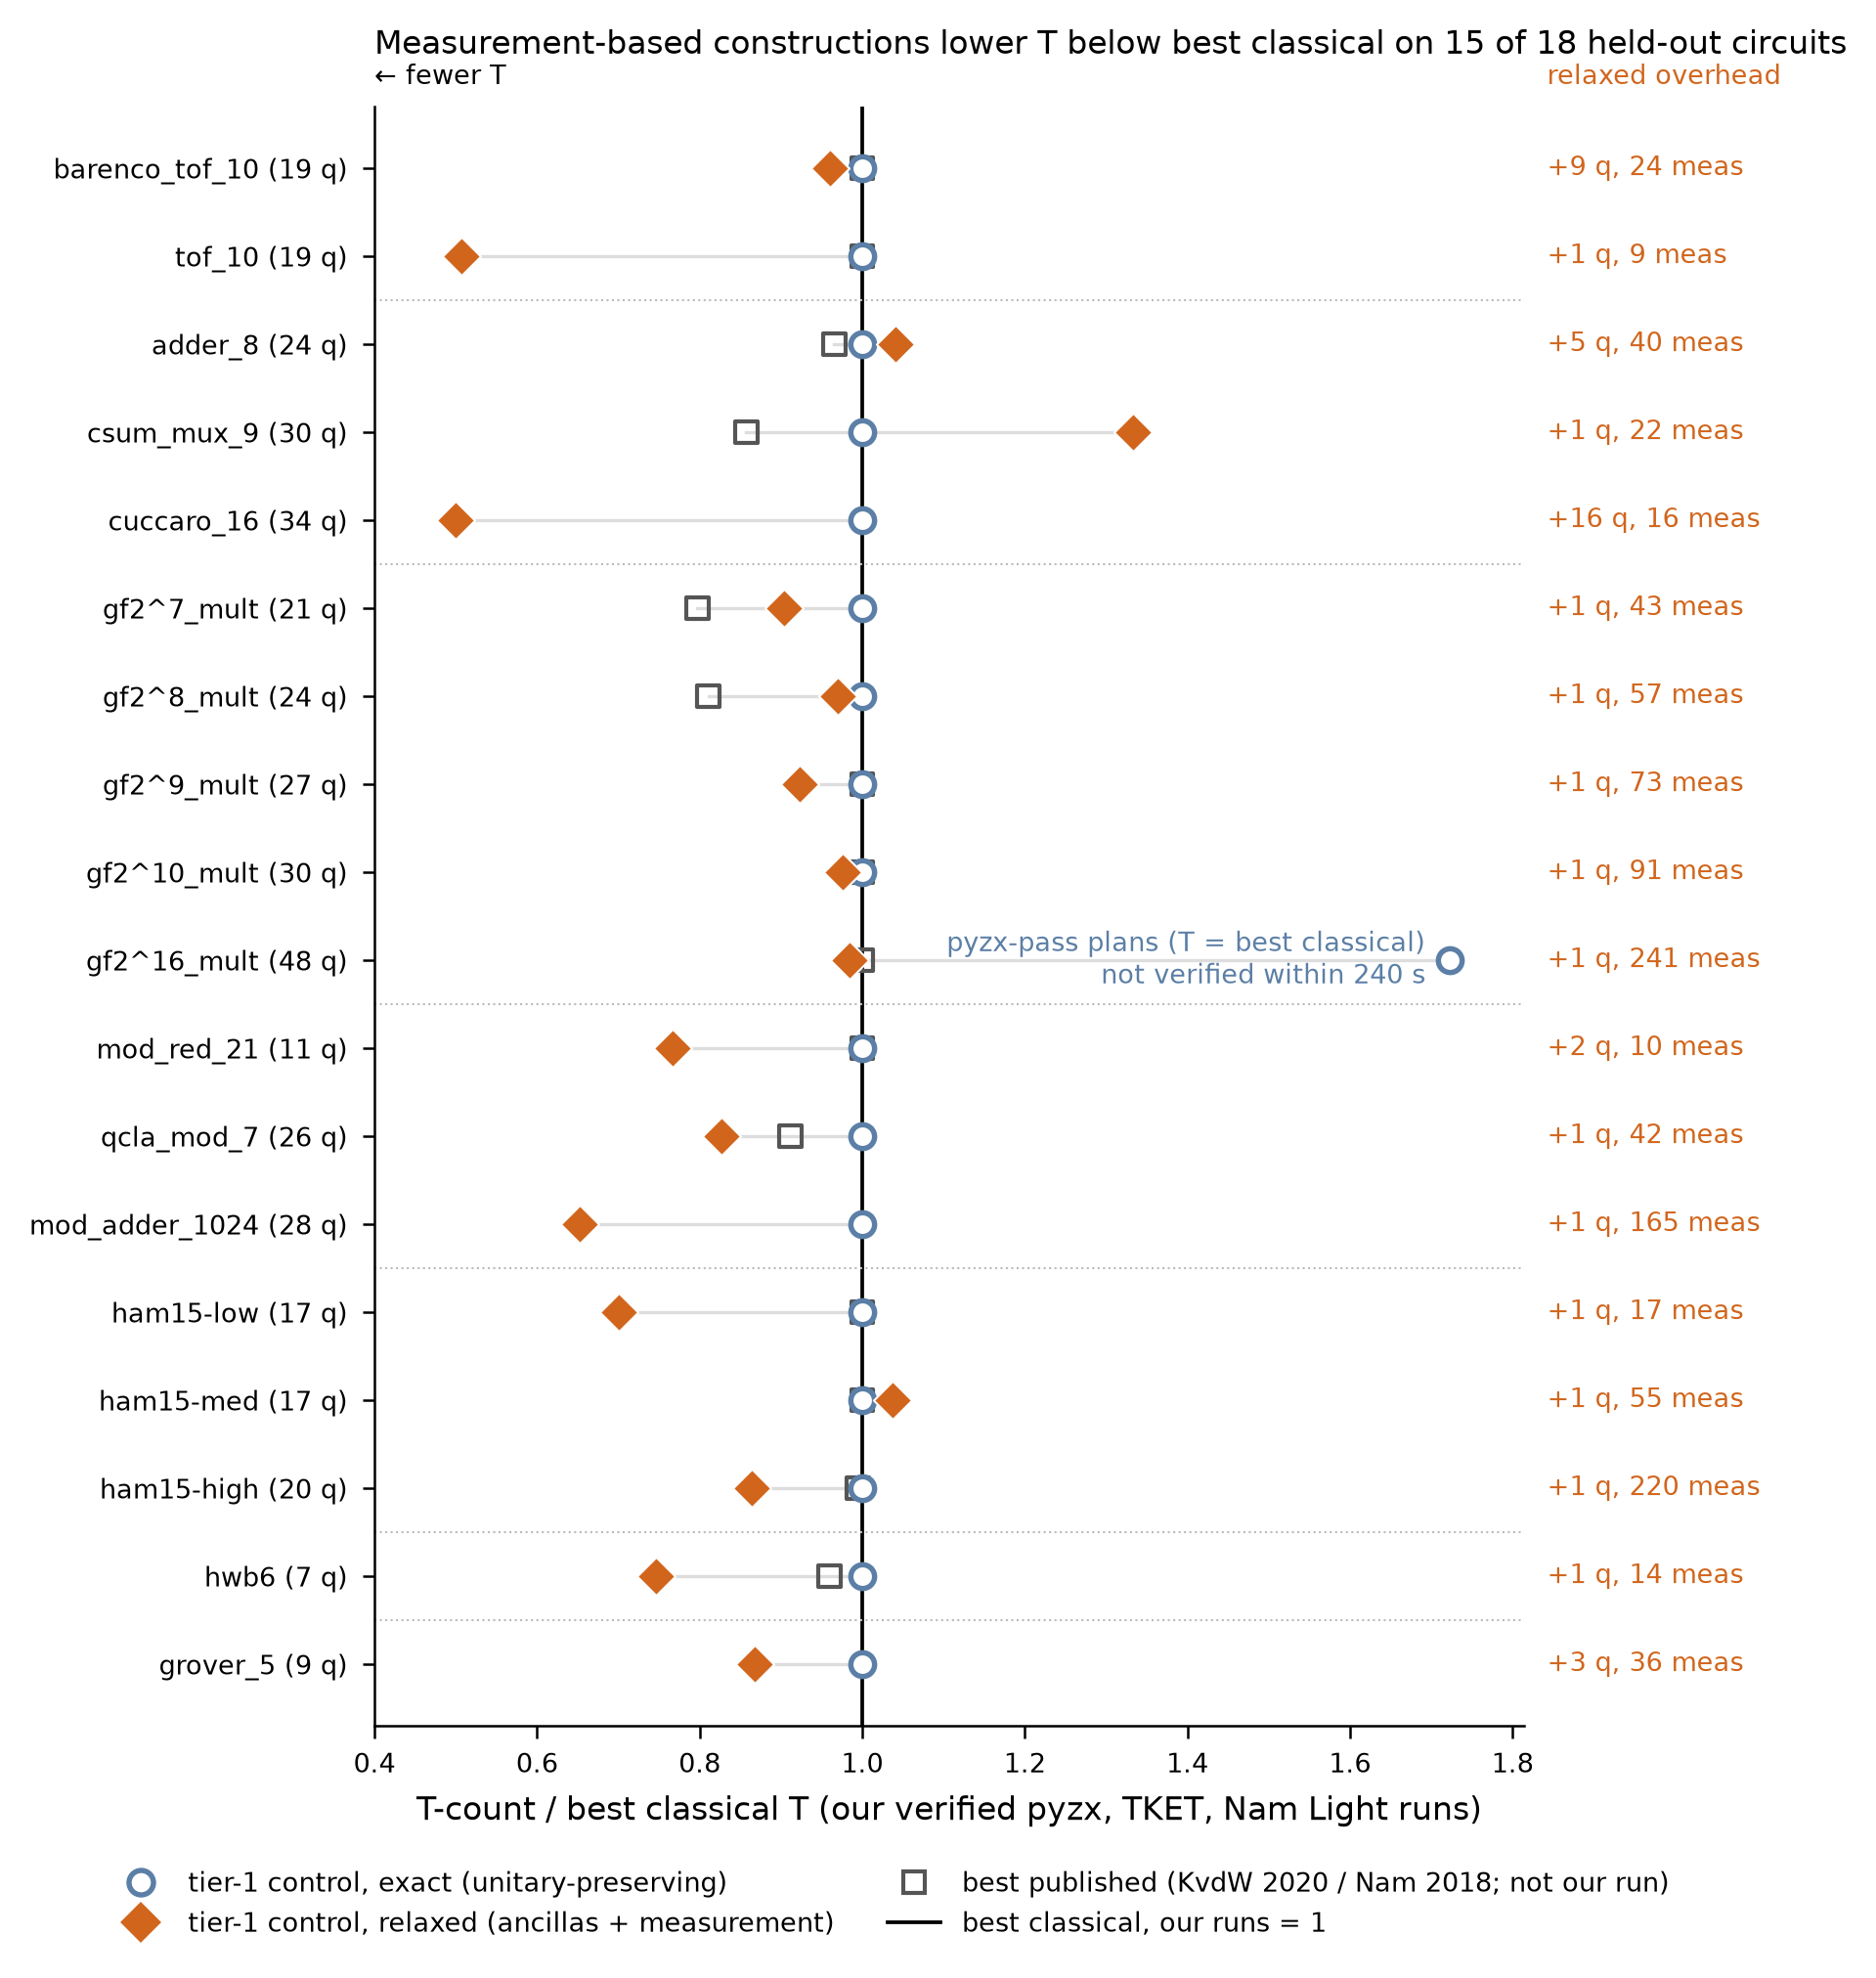

In [11]:
ev = pd.read_csv(R2 / "eval" / "eval_results.csv")
base = ev[ev.arm == "best_classical_ours"].set_index("circuit")
def arm(a, mode=None):
    x = ev[(ev.arm == a) & (ev["mode"] == mode)] if mode else ev[ev.arm == a]
    return x.set_index("circuit")
ex, rx = arm("tier1_control", "exact"), arm("tier1_control", "relaxed")
A = pd.DataFrame({"n": base.n.astype(int), "best_classical_ours": base.t_count, "arm": base.best_classical_ours_arm,
                  "tier1_exact": ex.t_count, "tier2_v0": arm("tier2_final").t_after,
                  "tier1+tier2_v0": arm("tier1+tier2_final").t_count,
                  "best_published": base.best_published_T, "check": ex.check})
print("A. unitary-preserving")
display(A)
B = pd.DataFrame({"best_classical_ours": base.t_count, "relaxed_T": rx.t_count, "ratio": (rx.t_count / base.t_count).round(2),
                  "qubits": rx.qubits.astype(int), "ancillas": rx.ancillas.astype(int), "measurements": rx.measurements.astype(int),
                  "zero_init_promise": rx.zero_qubits.fillna("none"), "variant": rx.variant + " + " + rx.global_pass, "check": rx.check})
print("B. relaxed (different contract)")
display(B)
SUM = dict(n=len(A), exact_eq=int((A.tier1_exact == A.best_classical_ours).sum()), exact_worse=int((A.tier1_exact > A.best_classical_ours).sum()),
           exact_better=int((A.tier1_exact < A.best_classical_ours).sum()), t2_changed=int((A.tier2_v0 != A.best_classical_ours).sum()),
           relaxed_lower=int((B.relaxed_T < B.best_classical_ours).sum()), relaxed_higher=int((B.relaxed_T > B.best_classical_ours).sum()),
           relaxed_total=int(B.relaxed_T.sum()), classical_total=int(B.best_classical_ours.sum()),
           min_lower=int((pd.concat([A.tier1_exact, B.relaxed_T], axis=1).min(axis=1) < A.best_classical_ours).sum()),
           pub_lower=int((A.best_published < A.best_classical_ours).sum()), pub_n=int(A.best_published.notna().sum()),
           anc_min=int(B.ancillas.min()), anc_max=int(B.ancillas.max()), meas_min=int(B.measurements.min()), meas_max=int(B.measurements.max()),
           variants=sorted(B.variant.unique()))
SUM["relaxed_pct"] = 100 * (SUM["relaxed_total"] / SUM["classical_total"] - 1)
print(SUM)
print("\nnot evaluated:")
for _, r in ev[ev.arm.isin(["skipped", "blocked"])].iterrows():
    print(f"  {r.circuit:14s} {r.arm:8s} {r.notes[:150]}")
display(Image(filename=str(R2 / "eval" / "eval_figure.png"), width=900))

## 7. Takeaways

Generated from the tables above (every number interpolated from the files read in sections 5-6).

In [12]:
t1x, t1r = TALLY1.set_index("mode").loc["exact"], TALLY1.set_index("mode").loc["relaxed"]
gap = int(d2.start_t.sum() - d2.best_classical_t.sum())
display(Markdown(f'''
1. **LLM arms are null in both tiers on DEV.** Tier 1: LLM vs control better {t1x.llm_better} / equal {t1x.equal} / worse {t1x.llm_worse}
   in exact mode and {t1r.llm_better} / {t1r.equal} / {t1r.llm_worse} (no valid plan on {t1r.llm_no_valid_plan}) in relaxed mode over
   {t1x.circuits} circuits. Tier 2: total DEV T {T2.start_T[0]} → {T2.final_T[0]} (LLM) and {T2.start_T[1]} → {T2.final_T[1]} (control); the
   frozen library is {lib.version} with {len(lib.rules)} rules. The verified LLM rule shown in section 4 matched {app.matches.sum()} times on
   the {len(app)} start circuits, and {diag['t_reducing_pool_rules_matching_any_start']} of {diag['pool_t_reducing']:,} enumerated T-reducing identities match anywhere.
2. **Measurement-based gains are known constructions applied by a fixed rule.** On held-out, the relaxed control is below the
   best classical unitary-preserving T on {SUM['relaxed_lower']}/{SUM['n']} circuits (higher on {SUM['relaxed_higher']}), total
   {SUM['relaxed_total']} vs {SUM['classical_total']} ({SUM['relaxed_pct']:+.1f} %), at +{SUM['anc_min']} to +{SUM['anc_max']} ancillas and
   {SUM['meas_min']}-{SUM['meas_max']} mid-circuit measurements. Every relaxed winner is {', '.join(SUM['variants'])}: Gidney temporary AND, Jones
   Toffoli and the compute-only AND, chosen by the deterministic control. On DEV cuccaro_8 the replayed LLM plan gives
   {naive['t_count']} → {ev8['t_count']} T vs {bc8['t_count']:.0f} for {bc8['arm']}; the control reaches {piv.loc['cuccaro_8', 'relaxed_control']:.0f} with the same budget.
3. **Unitary-preserving: no gain over the classical bar.** Held-out exact tier 1 equals our best classical run on {SUM['exact_eq']}/{SUM['n']}
   circuits (worse on {SUM['exact_worse']}, better on {SUM['exact_better']}); tier-2 v0 changes T on {SUM['t2_changed']}. Published values (mostly
   pyzx+TODD, Kissinger & van de Wetering 2020) are lower than our best run on {SUM['pub_lower']} of {SUM['pub_n']} held-out circuits with a published
   value; on DEV the tier-2 start circuits total {T2.start_T[0]} T vs {T2.best_classical_T[0]} for the best classical incl. published rows ({gap} T gap). That gap is non-local (Reed-Muller / TODD phase-polynomial optimization), which ≤ 4-qubit templates cannot express.
4. **Candidate next directions** (let the LLM choose *non-local* operations, each still verified):
   phase-polynomial regions to hand to a TODD-style optimizer; ancilla reuse across Toffoli gadgets (cuccaro_8 relaxed uses
   {ev8['qubits']} qubits vs {lc8.n}); Toffoli-network restructuring (e.g. carry computation into fresh ancillas, Karatsuba-style gf2 multiplication).
'''))


1. **LLM arms are null in both tiers on DEV.** Tier 1: LLM vs control better 0 / equal 16 / worse 0
   in exact mode and 0 / 13 / 2 (no valid plan on 1) in relaxed mode over
   16 circuits. Tier 2: total DEV T 758 → 758 (LLM) and 758 → 758 (control); the
   frozen library is v0 with 0 rules. The verified LLM rule shown in section 4 matched 0 times on
   the 16 start circuits, and 0 of 8,833 enumerated T-reducing identities match anywhere.
2. **Measurement-based gains are known constructions applied by a fixed rule.** On held-out, the relaxed control is below the
   best classical unitary-preserving T on 15/18 circuits (higher on 3), total
   4968 vs 5728 (-13.3 %), at +1 to +16 ancillas and
   9-241 mid-circuit measurements. Every relaxed winner is V2 + pyzx: Gidney temporary AND, Jones
   Toffoli and the compute-only AND, chosen by the deterministic control. On DEV cuccaro_8 the replayed LLM plan gives
   112 → 32 T vs 64 for pyzx_fr; the control reaches 32 with the same budget.
3. **Unitary-preserving: no gain over the classical bar.** Held-out exact tier 1 equals our best classical run on 17/18
   circuits (worse on 1, better on 0); tier-2 v0 changes T on 0. Published values (mostly
   pyzx+TODD, Kissinger & van de Wetering 2020) are lower than our best run on 7 of 15 held-out circuits with a published
   value; on DEV the tier-2 start circuits total 758 T vs 652 for the best classical incl. published rows (106 T gap). That gap is non-local (Reed-Muller / TODD phase-polynomial optimization), which ≤ 4-qubit templates cannot express.
4. **Candidate next directions** (let the LLM choose *non-local* operations, each still verified):
   phase-polynomial regions to hand to a TODD-style optimizer; ancilla reuse across Toffoli gadgets (cuccaro_8 relaxed uses
   26 qubits vs 18); Toffoli-network restructuring (e.g. carry computation into fresh ancillas, Karatsuba-style gf2 multiplication).


In [13]:
V.check_integrity()
print(f"frozen verifier digest unchanged: {integrity.frozen_digest() == DIGEST0}; notebook runtime {time.time() - T0:.1f} s")

frozen verifier digest unchanged: True; notebook runtime 9.2 s
